# Lecture 9. Proximal gradient methods

**Convex optimization, Fall 2026**

> A proximal step keeps the smooth piece explicit and treats the convex piece implicitly: the next point minimizes that piece plus a quadratic centered at a gradient step.

- Lecture 6 stepped along $-\,f'$ by explicit Euler on the gradient flow $\dot{\mathbf{x}}=-f'(\mathbf{x})$.
- Today the objective may split. The smooth piece is still a gradient step. A convex piece with a cheap proximal map is one minimization, possibly nonsmooth.
- Levenberg–Marquardt is that minimization applied to a Gauss–Newton model of a nonlinear least-squares loss. On that model it is also a trust-region step.
- The rest of the lecture is the proximal gradient method for $\min\,(f+g)$, the $1/k$ guarantee and its accelerated $1/k^2$ form, and two problems whose proximal maps are closed forms: a sparse logistic loss, and a nuclear-norm fit on a matrix.


## Plan

1. The proximal operator, the implicit Euler reading, and Levenberg–Marquardt on a nonlinear least-squares model. Trust-region methods for the same model, and what an efficient implementation stores.
2. Properties of the proximal operator, and maps with a closed form, including separable functions.
3. The composite problem and the proximal gradient iteration.
4. Convergence: descent, the $1/k$ gap, the linear rate under strong convexity.
5. Acceleration, by the scheme of lecture 7 with a proximal step in place of the gradient step.
6. Two uses: a sparse logistic loss on a vector, and a nuclear-norm loss on a matrix.

- Notation is lecture 1's. $\|\cdot\|$ is the Euclidean norm, $f'$ is the gradient, $f^\star$ is the optimal value.
- $L$-smoothness and strong convexity are the definitions from lectures 2 and 6. The step $\eta=1/L$ is the step those lectures used.
- The notebook uses NumPy and Matplotlib only.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
plt.rcParams.update(
    {
        "figure.figsize": (7.2, 4.0),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 12,
        "axes.titlesize": 13,
        "legend.fontsize": 10,
    }
)


# 1. The proximal operator

- Let $g$ be convex, closed, and proper. For a step $\eta>0$ the **proximal operator** is

$$
\operatorname{prox}_{\eta g}(\mathbf{v})
=
\arg\min_{\mathbf{x}}
\left(
g(\mathbf{x})+\frac{1}{2\eta}\|\mathbf{x}-\mathbf{v}\|^2
\right).
$$

- The quadratic is strongly convex, so the minimizer exists and is unique.
- The same point is characterized by a subgradient. $\mathbf{x}^+=\operatorname{prox}_{\eta g}(\mathbf{v})$ if and only if

$$
\frac{\mathbf{v}-\mathbf{x}^+}{\eta}\in\partial g(\mathbf{x}^+),
$$

and, written without a subgradient, if and only if every $\mathbf{y}$ satisfies

$$
g(\mathbf{y})
\ge
g(\mathbf{x}^+)
+\frac{1}{\eta}\langle \mathbf{v}-\mathbf{x}^+,\,\mathbf{y}-\mathbf{x}^+\rangle.
$$

- A minimizer of $g$ is a fixed point of every proximal map: $\mathbf{x}^\star\in\arg\min g$ if and only if $\mathbf{x}^\star=\operatorname{prox}_{\eta g}(\mathbf{x}^\star)$. The vector $(\mathbf{v}-\mathbf{x}^+)/\eta$ is then zero, which is the subgradient condition for an unconstrained minimum of $g$.


## Implicit Euler on the gradient flow

- The gradient flow of a smooth $f$ is the ODE $\dot{\mathbf{x}}=-f'(\mathbf{x})$.
- **Explicit Euler** with step $\eta$ reads the slope at the current point,

$$
\mathbf{x}^{k+1}=\mathbf{x}^k-\eta\, f'(\mathbf{x}^k).
$$

- That is gradient descent. Lecture 6 proved that $\eta\in(0,2/L)$ is the range in which one step of an $L$-smooth function is guaranteed to decrease, and that $\eta>2/L$ can make a quadratic grow.
- **Implicit Euler** reads the slope at the next point,

$$
\mathbf{x}^{k+1}=\mathbf{x}^k-\eta\, f'(\mathbf{x}^{k+1}).
$$

- Rearranged, $(\mathbf{x}^k-\mathbf{x}^{k+1})/\eta=f'(\mathbf{x}^{k+1})$. For a differentiable $f$ this is the subgradient relation above, so

$$
\mathbf{x}^{k+1}
=
\operatorname{prox}_{\eta f}(\mathbf{x}^k)
=
\arg\min_{\mathbf{y}}
\left(
f(\mathbf{y})+\frac{1}{2\eta}\|\mathbf{y}-\mathbf{x}^k\|^2
\right).
$$

- The iteration that repeats this minimization is the **proximal point** method. Every $\eta>0$ is legal when $f$ is convex: the map is firmly nonexpansive, and there is no $2/L$ threshold to cross.
- On the quadratic $f(t)=(L/2)t^2$ the two steps are scalar and exact. Explicit Euler multiplies by $1-\eta L$. Implicit Euler multiplies by $1/(1+\eta L)$, which lies in $(0,1)$ for every $\eta>0$.


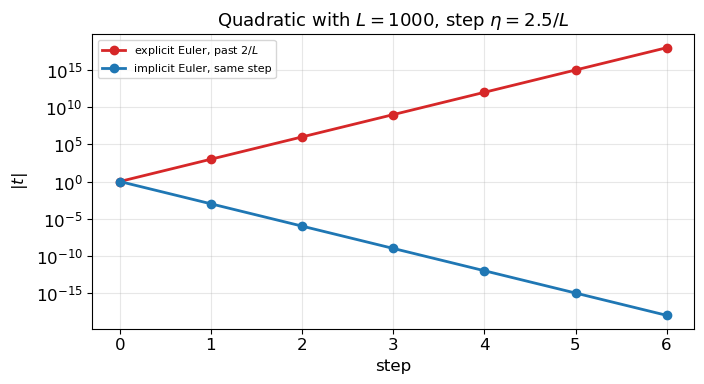

explicit factor -999.000, after 6 steps t=994014980014994048.0000, f=494032890247104539723716271570421809152.0
implicit factor 0.001, after 6 steps t=9.940e-19, f=4.940e-34
explicit step 1/L from t=1 lands at 0


In [5]:
# f(t) = (L/2) t^2, minimizer at 0. L = 40, so the explicit threshold 2/L is 0.05.
L_quad = 1000.0
eta_long = 1000 / L_quad  # past 2/L: explicit Euler is unstable
factor_explicit = 1.0 - eta_long * L_quad
factor_implicit = 1.0 / (1.0 + eta_long * L_quad)

explicit = [1.0]
implicit = [1.0]
for _ in range(6):
    explicit.append(explicit[-1] * factor_explicit)
    implicit.append(implicit[-1] * factor_implicit)
explicit = np.array(explicit)
implicit = np.array(implicit)

fig, ax = plt.subplots()
steps = np.arange(7)
ax.plot(steps, np.abs(explicit), "o-", color="C3", lw=2, label="explicit Euler, past $2/L$")
ax.plot(steps, np.abs(implicit), "o-", color="C0", lw=2, label="implicit Euler, same step")
ax.set_yscale("log")
ax.set_xlabel("step")
ax.set_ylabel(r"$|t|$")
ax.set_title(rf"Quadratic with $L={L_quad:.0f}$, step $\eta=2.5/L$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"explicit factor {factor_explicit:.3f}, after 6 steps t={explicit[-1]:.4f}, f={0.5 * L_quad * explicit[-1] ** 2:.1f}")
print(f"implicit factor {factor_implicit:.3f}, after 6 steps t={implicit[-1]:.3e}, f={0.5 * L_quad * implicit[-1] ** 2:.3e}")
print(f"explicit step 1/L from t=1 lands at {1.0 - (1.0 / L_quad) * L_quad:.0f}")


## Reading the two discretizations

- The step $\eta=2.5/L$ multiplies the explicit iteration by $-1.5$. After six steps the coordinate is $11.39$ and the value is $2594.9$, up from $f(1)=20$. This is the same threshold as lecture 6: past $2/L$ the stiff eigenvalue is expanded.
- The implicit step multiplies by $1/3.5\approx 0.286$. After six steps the coordinate is $5.44\times 10^{-4}$ and the value is $5.92\times 10^{-6}$. The step that destabilizes explicit Euler is a contraction for implicit Euler.
- The step $1/L$ is a different comparison. On this quadratic it sends $t=1$ to the minimizer in one explicit step, because the model of lecture 6 is the function. Implicit Euler at that same step only multiplies by $1/2$. The implicit method buys a step-size restriction that is gone; on a quadratic it pays for that with a shorter step than $1/L$.


## Levenberg–Marquardt is a proximal step on a model

- A nonlinear least-squares loss has the shape

$$
\varphi(\mathbf{x})=\frac12\|\mathbf{r}(\mathbf{x})\|^2,
\qquad
\mathbf{r}:\mathbb{R}^n\to\mathbb{R}^m.
$$

- The gradient is $\varphi'(\mathbf{x})=J(\mathbf{x})^\top \mathbf{r}(\mathbf{x})$, with $J$ the Jacobian of $\mathbf{r}$. The Hessian adds a second term, $\sum_i r_i(\mathbf{x})\, r_i''(\mathbf{x})$, to $J^\top J$.
- **Gauss–Newton** drops that second term and minimizes the linear model of the residual,

$$
m(\mathbf{d})
=
\frac12\|\mathbf{r}+J\mathbf{d}\|^2
=
\varphi
+\langle J^\top\mathbf{r},\,\mathbf{d}\rangle
+\frac12\|J\mathbf{d}\|^2.
$$

- The minimizer solves $J^\top J\,\mathbf{d}=-J^\top\mathbf{r}$. One undamped step can raise $\varphi$, for the same reason an undamped Newton step raised the value on Rosenbrock in lecture 8: the model is trusted outside the region where it describes $\varphi$.
- **Levenberg–Marquardt** puts a proximal term on that model,

$$
\mathbf{d}_{\lambda}
=
\arg\min_{\mathbf{d}}
\left(
m(\mathbf{d})+\frac{\lambda}{2}\|\mathbf{d}\|^2
\right),
\qquad
(J^\top J+\lambda I)\,\mathbf{d}=-J^\top\mathbf{r}.
$$

- This is one proximal-point step on $m$, with step length $\eta=1/\lambda$. A full proximal-point step on $\varphi$ itself would minimize $\varphi(\mathbf{x}+\mathbf{d})+(\lambda/2)\|\mathbf{d}\|^2$. Levenberg–Marquardt replaces $\varphi$ by the Gauss–Newton model and leaves the proximal term in place. Small $\lambda$ recovers Gauss–Newton. Large $\lambda$ recovers a short gradient step on $\varphi$.


## Trust region, on the same model

- A **trust-region** step minimizes the same model inside a ball whose radius is chosen explicitly,

$$
\min_{\mathbf{d}}\; m(\mathbf{d})
\quad\text{subject to}\quad
\|\mathbf{d}\|\le \Delta.
$$

- The stationarity condition of this constrained quadratic is

$$
(J^\top J+\lambda I)\,\mathbf{d}=-J^\top\mathbf{r},
\qquad
\lambda\ge 0,
\qquad
\lambda\,(\|\mathbf{d}\|-\Delta)=0.
$$

- So every trust-region step on $m$ is a Levenberg–Marquardt step. If the Gauss–Newton step lies inside the ball, then $\lambda=0$. Otherwise $\lambda>0$ is the multiplier that puts $\|\mathbf{d}\|$ on the sphere of radius $\Delta$. The two algorithms control different variables: Levenberg–Marquardt updates $\lambda$, a trust-region method updates $\Delta$.
- Both score a candidate by the ratio of actual decrease to model decrease,

$$
\rho
=
\frac{\varphi(\mathbf{x})-\varphi(\mathbf{x}+\mathbf{d})}{m(\mathbf{0})-m(\mathbf{d})}.
$$

- A small $\rho$ says the model was optimistic: Levenberg–Marquardt increases $\lambda$, and a trust-region method shrinks $\Delta$, and the step can be rejected. A $\rho$ near $1$ says the model was accurate, and the control variable is relaxed.
- **Powell's dogleg** builds an approximate trust-region step from two vectors. The Cauchy point is the minimizer of $m$ along $-\,m'(\mathbf{0})$. The Gauss–Newton step is the unconstrained minimizer. The dogleg is the broken line from the origin to the Cauchy point to the Gauss–Newton step, cut by the sphere $\|\mathbf{d}\|=\Delta$. It costs one factorization of $J^\top J$ and no search over $\lambda$. The convergence theory of trust regions needs the Cauchy decrease, which this path provides.
- An exact trust-region step searches for the $\lambda$ with $\|\mathbf{d}_\lambda\|=\Delta$. Each trial factors $J^\top J+\lambda I$. The derivative of $\|\mathbf{d}_\lambda\|$ with respect to $\lambda$ is available from one extra triangular solve, so the search is a scalar Newton iteration.
- At large $n$ the factorization is the wrong object. **Steihaug–CG** is the truncated conjugate-gradient iteration of lecture 8, with the sphere as one more exit: stop when the CG path crosses $\|\mathbf{d}\|=\Delta$. For this model the product required by CG is $J^\top(J\mathbf{v})$, two Jacobian products and no matrix $J^\top J$.


## What an efficient solve stores

- The linear equation $(J^\top J+\lambda I)\mathbf{d}=-J^\top\mathbf{r}$ is the normal equation of an augmented least-squares problem,

$$
\min_{\mathbf{d}}
\left\|
\begin{pmatrix} J \\ \sqrt{\lambda}\, I \end{pmatrix}
\mathbf{d}
+
\begin{pmatrix} \mathbf{r} \\ \mathbf{0} \end{pmatrix}
\right\|.
$$

- Forming $J^\top J$ squares the condition number. A QR factorization of the augmented matrix has the square root of that condition number, and it is the factorization to use whenever $J$ itself is ill-conditioned. A sparse or structured $J$ never needs to be stored as $J^\top J$: LSQR solves the augmented problem from products $J\mathbf{v}$ and $J^\top\mathbf{u}$.
- Dogleg stores one factor of $J^\top J$ and the radius $\Delta$. Exact trust region stores a short sequence of factors $J^\top J+\lambda I$. Steihaug–CG stores a few vectors and the radius. Levenberg–Marquardt stores $\lambda$ and one augmented factor per accepted step.

| | Gauss–Newton | Levenberg–Marquardt | Dogleg | Exact trust region | Steihaug–CG |
|---|---|---|---|---|---|
| Control | none | $\lambda$ | $\Delta$ | $\Delta$, solved in $\lambda$ | $\Delta$ |
| Linear algebra per try | one least squares | one augmented least squares | one factor of $J^\top J$ | a factor of $J^\top J+\lambda I$, a few times | Jacobian products |
| The step it returns | unconstrained minimizer of $m$ | proximal minimizer of $m$ | a point on the Cauchy–Gauss–Newton path | the minimizer of $m$ in the ball | a CG point inside the ball |

- The model in the cell is the one a navigation receiver solves. Anchors with known coordinates sit on a floor of about $40$ metres, and the receiver measures a pseudorange to each of them,

$$
\rho_i=\|\mathbf{x}-\mathbf{s}_i\|+b.
$$

- The unknown is the position $\mathbf{x}$ in the plane and a clock bias $b$, both in metres. The bias is the GNSS convention: a clock error stated as a range. Six anchors determine the three unknowns. The same residual, with satellites in place of the anchors, is the update inside a GNSS receiver, and it is the standard nonlinear least-squares problem in positioning.
- The receiver is started at the wrong corner of the floor, $(55,\,5)$, with the bias still zero. That is where an undamped step and a damped step part company. A separate linear problem, whose Jacobian has condition number $10^8$, is where forming $J^\top J$ matters.


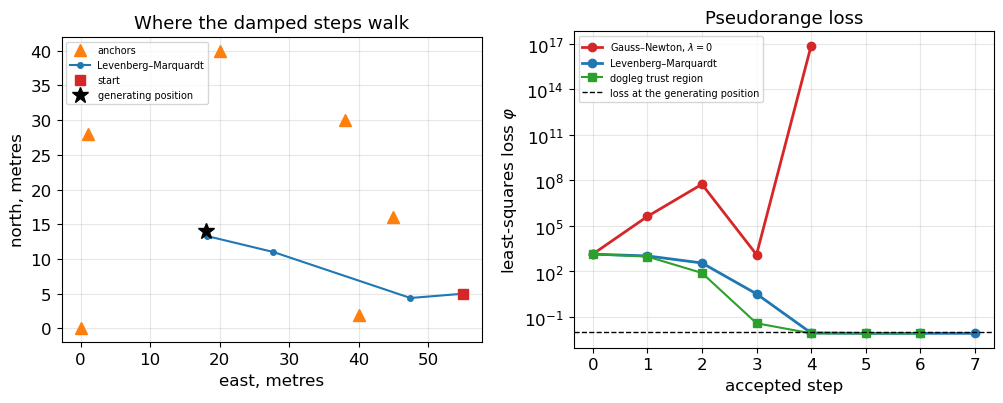

loss at the start 1379.839, loss at the generating position 0.0098
Gauss–Newton losses: [1.380e+03 4.166e+05 5.477e+07 1.283e+03 7.160e+16]
first undamped step length 307.8 m, lands at (-165.3, 84.0), bias 200.0 m
LM ends at x=17.982, y=14.012, bias=3.513, loss 0.00850
dogleg ends at x=17.982, y=14.012, bias=3.513, loss 0.00850
position error 0.022 m
cond(J) = 1.00e+08, cond(J^T J) = 1.17e+16
relative error, QR 2.47e-10, normal equations 1.00e+00
residual, QR 3.85e-17, normal equations 1.00e-08


In [6]:
def pseudorange_fix():
    # A receiver on a 40 m floor, six anchors, one clock bias. This is the
    # GNSS pseudorange model with the satellites replaced by indoor anchors.
    rng_fix = np.random.default_rng(0)
    anchors = np.array(
        [[0.0, 0.0], [40.0, 2.0], [38.0, 30.0], [1.0, 28.0], [20.0, 40.0], [45.0, 16.0]]
    )
    truth = np.array([18.0, 14.0, 3.5])
    geometric = np.linalg.norm(anchors - truth[:2], axis=1)
    ranges = geometric + truth[2] + rng_fix.normal(scale=0.15, size=anchors.shape[0])

    def residual(p):
        predicted = np.linalg.norm(anchors - p[:2], axis=1) + p[2]
        return ranges - predicted

    def jacobian(p):
        # Row i is the derivative of measured range minus predicted range.
        offset = p[:2] - anchors
        distance = np.maximum(np.linalg.norm(offset, axis=1), 1e-8)
        direction = offset / distance[:, None]
        return np.column_stack([-direction, -np.ones(anchors.shape[0])])

    def objective(p):
        r = residual(p)
        return 0.5 * float(r @ r)

    def step_at(p, lam):
        J = jacobian(p)
        r = residual(p)
        g = J.T @ r
        B = J.T @ J
        d = np.linalg.solve(B + lam * np.eye(p.size), -g)
        return d, g, B

    def model_decrease(g, B, d):
        # Decrease of the Gauss–Newton model m(d) = (1/2)||r + J d||^2.
        return float(-g @ d - 0.5 * d @ (B @ d))

    def dogleg(g, B, radius):
        gn = np.linalg.solve(B, -g)
        g_norm = float(np.linalg.norm(g))
        curvature = float(g @ (B @ g))
        if g_norm == 0.0 or curvature <= 0.0:
            return np.zeros_like(g)
        cauchy = -(g_norm ** 2 / curvature) * g
        if np.linalg.norm(cauchy) >= radius:
            return -(radius / g_norm) * g
        if np.linalg.norm(gn) <= radius:
            return gn
        diff = gn - cauchy
        aa = float(diff @ diff)
        bb = 2.0 * float(cauchy @ diff)
        cc = float(cauchy @ cauchy) - radius ** 2
        tau = (-bb + np.sqrt(bb * bb - 4.0 * aa * cc)) / (2.0 * aa)
        return cauchy + tau * diff

    start = np.array([55.0, 5.0, 0.0])
    floor = objective(truth)

    gn_values = [objective(start)]
    gn_landing = None
    gn_length = None
    p = start.copy()
    for step_index in range(4):
        d, _, _ = step_at(p, 0.0)
        p = p + d
        gn_values.append(objective(p))
        if step_index == 0:
            gn_landing = p.copy()
            gn_length = float(np.linalg.norm(d))

    def levenberg_marquardt(n_iter=10):
        p = start.copy()
        lam = 1.0
        values = [objective(p)]
        path = [p.copy()]
        for _ in range(n_iter):
            d, g, B = step_at(p, lam)
            if np.linalg.norm(d) < 1e-8:
                break
            predicted = model_decrease(g, B, d)
            actual = objective(p) - objective(p + d)
            rho = actual / predicted
            if rho > 0.25:
                p = p + d
                path.append(p.copy())
                if rho > 0.75:
                    lam = max(lam / 3.0, 1e-8)
            else:
                lam = min(lam * 3.0, 1e8)
            values.append(objective(p))
        return p, np.array(values), np.array(path)

    def trust_region(n_iter=10):
        p = start.copy()
        radius = 12.0
        values = [objective(p)]
        for _ in range(n_iter):
            J = jacobian(p)
            r = residual(p)
            g = J.T @ r
            B = J.T @ J
            d = dogleg(g, B, radius)
            if np.linalg.norm(d) < 1e-8:
                break
            predicted = model_decrease(g, B, d)
            actual = objective(p) - objective(p + d)
            rho = actual / predicted
            if rho > 0.1:
                p = p + d
            if rho < 0.25:
                radius *= 0.25
            elif rho > 0.75 and abs(np.linalg.norm(d) - radius) <= 1e-8 * radius:
                radius = min(2.0 * radius, 80.0)
            values.append(objective(p))
        return p, np.array(values)

    lm_p, lm_values, lm_path = levenberg_marquardt()
    tr_p, tr_values = trust_region()
    return {
        "anchors": anchors,
        "start_p": start,
        "truth": truth,
        "start": objective(start),
        "floor": floor,
        "gn": np.array(gn_values),
        "gn_landing": gn_landing,
        "gn_length": gn_length,
        "lm": lm_values,
        "lm_p": lm_p,
        "lm_path": lm_path,
        "tr": tr_values,
        "tr_p": tr_p,
    }


def ill_conditioned_least_squares():
    # J has singular values from 1 down to 1e-8. The right-hand side lies along
    # the most sensitive right singular vector, so the normal equation feels it.
    rng_ls = np.random.default_rng(1)
    m, n = 40, 8
    u, _ = np.linalg.qr(rng_ls.normal(size=(m, n)))
    v, _ = np.linalg.qr(rng_ls.normal(size=(n, n)))
    singular = np.logspace(0.0, -8.0, n)
    J = (u[:, :n] * singular) @ v.T
    d_true = v[:, -1]
    rhs = J @ d_true
    d_qr = np.linalg.lstsq(J, rhs, rcond=None)[0]
    d_normal = np.linalg.lstsq(J.T @ J, J.T @ rhs, rcond=None)[0]
    return {
        "cond_J": np.linalg.cond(J),
        "cond_normal": np.linalg.cond(J.T @ J),
        "rel_qr": np.linalg.norm(d_qr - d_true) / np.linalg.norm(d_true),
        "rel_normal": np.linalg.norm(d_normal - d_true) / np.linalg.norm(d_true),
        "resid_qr": np.linalg.norm(J @ d_qr - rhs),
        "resid_normal": np.linalg.norm(J @ d_normal - rhs),
    }


fix = pseudorange_fix()
linear = ill_conditioned_least_squares()

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.2))
ax = axes[0]
ax.plot(fix["anchors"][:, 0], fix["anchors"][:, 1], "^", color="C1", ms=8, label="anchors")
ax.plot(fix["lm_path"][:, 0], fix["lm_path"][:, 1], "o-", color="C0", ms=4, lw=1.5, label="Levenberg–Marquardt")
ax.plot(fix["start_p"][0], fix["start_p"][1], "s", color="C3", ms=7, label="start")
ax.plot(fix["truth"][0], fix["truth"][1], "*", color="k", ms=12, label="generating position")
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("east, metres")
ax.set_ylabel("north, metres")
ax.set_title("Where the damped steps walk")
ax.legend(fontsize=7, loc="upper left")
ax = axes[1]
ax.semilogy(np.arange(fix["gn"].size), fix["gn"], "o-", color="C3", lw=2, label="Gauss–Newton, $\\lambda=0$")
ax.semilogy(np.arange(fix["lm"].size), fix["lm"], "o-", color="C0", lw=2, label="Levenberg–Marquardt")
ax.semilogy(np.arange(fix["tr"].size), fix["tr"], "s-", color="C2", lw=1.5, label="dogleg trust region")
ax.axhline(fix["floor"], color="k", ls="--", lw=1, label="loss at the generating position")
ax.set_xlabel("accepted step")
ax.set_ylabel(r"least-squares loss $\varphi$")
ax.set_title("Pseudorange loss")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

print(f"loss at the start {fix['start']:.3f}, loss at the generating position {fix['floor']:.4f}")
print(f"Gauss–Newton losses: {np.array2string(fix['gn'], precision=3)}")
print(
    f"first undamped step length {fix['gn_length']:.1f} m, "
    f"lands at ({fix['gn_landing'][0]:.1f}, {fix['gn_landing'][1]:.1f}), "
    f"bias {fix['gn_landing'][2]:.1f} m"
)
print(
    f"LM ends at x={fix['lm_p'][0]:.3f}, y={fix['lm_p'][1]:.3f}, "
    f"bias={fix['lm_p'][2]:.3f}, loss {fix['lm'][-1]:.5f}"
)
print(
    f"dogleg ends at x={fix['tr_p'][0]:.3f}, y={fix['tr_p'][1]:.3f}, "
    f"bias={fix['tr_p'][2]:.3f}, loss {fix['tr'][-1]:.5f}"
)
print(f"position error {np.linalg.norm(fix['lm_p'][:2] - fix['truth'][:2]):.3f} m")
print(f"cond(J) = {linear['cond_J']:.2e}, cond(J^T J) = {linear['cond_normal']:.2e}")
print(f"relative error, QR {linear['rel_qr']:.2e}, normal equations {linear['rel_normal']:.2e}")
print(f"residual, QR {linear['resid_qr']:.2e}, normal equations {linear['resid_normal']:.2e}")


## Reading the fix and the factorization

- The loss starts at $1380$. At the position and bias that generated the ranges it is $0.0098$. The range noise has scale $0.15$ metres, and there are six anchors.
- Undamped Gauss–Newton raises the loss from $1380$ to $4.17\times 10^{5}$ on the first step. That step is $307.8$ metres long and lands at $(-165.3,\,84.0)$, off the floor, with a clock bias of $200$ metres. The linear model of the ranges was minimized with no limit on $\|\mathbf{d}\|$, and a range is not a linear function that far from the anchors. By the fourth step the loss is $7.16\times 10^{16}$. One intermediate value is smaller, which is an accident of where the step landed: the iteration accepted every step, including the first increase.
- Levenberg–Marquardt, started at $\lambda=1$ and updated by factors of three according to $\rho$, decreases at every accepted step. On the map the receiver walks from $(55,\,5)$ across the floor and finishes at $(17.982,\,14.012)$, bias $3.513$, against the generating value $(18,\,14,\,3.5)$. The position error is $0.022$ metres. The loss is $0.00850$, just under the loss at the generating position, because the fit absorbs the range noise. The dogleg trust region, started at a radius of $12$ metres, finishes at the same point and the same loss. The radius is in metres because the unknown is a position in metres, and a step of $307.8$ metres is the step that radius is there to refuse. The two control variables produce the same fix. They differ in cost when $J^\top J$ is expensive: dogleg factors it once per outer iteration, and a $\lambda$-update may factor several augmented matrices before a step is accepted.
- The linear problem is a different fact. $J$ has condition number $1.00\times 10^{8}$, so $J^\top J$ has condition number $1.17\times 10^{16}$, which is past $1/\varepsilon_{\mathrm{mach}}$ in float64. The QR solution of $J\mathbf{d}=\mathbf{b}$ has relative error $2.47\times 10^{-10}$. The solution of the normal equation has relative error $1.0$: the small singular direction, which is where the true $\mathbf{d}$ sits, is gone. Forming $J^\top J$ is the step that loses it.


# 2. Properties, and maps with a closed form

- The proximal map of a convex $g$ is **firmly nonexpansive**: for every $\mathbf{u},\mathbf{v}$,

$$
\|\operatorname{prox}_{\eta g}(\mathbf{u})-\operatorname{prox}_{\eta g}(\mathbf{v})\|^2
\le
\langle
\operatorname{prox}_{\eta g}(\mathbf{u})-\operatorname{prox}_{\eta g}(\mathbf{v}),\,
\mathbf{u}-\mathbf{v}
\rangle.
$$

- Firm nonexpansiveness implies nonexpansiveness, $\|\operatorname{prox}(\mathbf{u})-\operatorname{prox}(\mathbf{v})\|\le\|\mathbf{u}-\mathbf{v}\|$. A proximal step cannot increase distances. Gradient descent has no such guarantee once the step exceeds $2/L$.
- **Separable** $g(\mathbf{x})=\sum_i g_i(x_i)$ has a separable proximal map. The objective in the definition splits into a sum of scalar functions of one coordinate, so the minimizer does too. The same holds for a sum over disjoint blocks: the proximal map of $\lambda\sum_b \|\mathbf{x}_b\|_2$ is a block soft threshold, $\mathbf{x}_b\leftarrow (1-\lambda/\|\mathbf{v}_b\|)_+\mathbf{v}_b$.


## Four maps

- **Soft threshold**, the proximal map of $t\|\cdot\|_1$:

$$
\bigl(\operatorname{prox}_{t\|\cdot\|_1}(\mathbf{v})\bigr)_i
=
\operatorname{sign}(v_i)\,\max(|v_i|-t,\,0).
$$

- **Clipping** to $[-t,t]$, the proximal map of the indicator of that box
- **Projection onto a convex set** $C$ is the proximal map of the indicator $\iota_C$. 
    - The nonnegative orthant gives $\max(v_i,0)$. 
    - A box $[\ell_i,u_i]$ gives the coordinate-wise median of $\ell_i$, $v_i$, and $u_i$. 
    - The probability simplex $\{\mathbf{x}\ge 0,\;\sum_i x_i=1\}$ is the projection from lecture 3: shift by one $\tau$ and keep the positive part, with $\tau$ chosen so the positive parts sum to $1$.
- **Singular-value soft threshold**, the proximal map of $t\|\cdot\|_*$ on matrices. If $Y=U\operatorname{diag}(\sigma)V^\top$ is a singular-value decomposition, the proximal map replaces $\sigma_i$ by $\max(\sigma_i-t,\,0)$. Section 6 uses it as the matrix step. The scalar soft threshold is the same rule on a diagonal matrix.


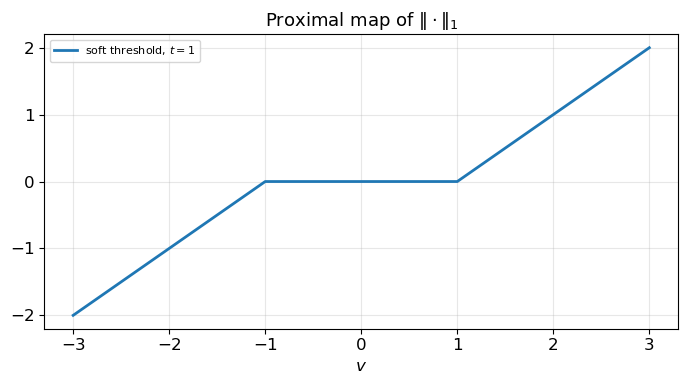

soft threshold, largest distance ratio over 399 pairs: 0.911
simplex input  [ 0.2  0.9 -0.4  0.3  0.1]
simplex output [0.067 0.767 0.    0.167 0.   ]
simplex sum 1.00, smallest entry 0.00


In [7]:
def soft_threshold(v, level):
    return np.sign(v) * np.maximum(np.abs(v) - level, 0.0)


def project_simplex(v):
    # Projection onto {x >= 0, sum x = 1}: one shift, then the positive part.
    order = np.sort(v)[::-1]
    cumulative = np.cumsum(order)
    idx = np.arange(1, v.size + 1)
    positive = np.where(order - (cumulative - 1.0) / idx > 0.0)[0]
    rho = positive[-1]
    tau = (cumulative[rho] - 1.0) / (rho + 1.0)
    return np.maximum(v - tau, 0.0)


level = 1.0
grid = np.linspace(-3.0, 3.0, 400)
fig, ax = plt.subplots()
ax.plot(grid, soft_threshold(grid, level), color="C0", lw=2, label=r"soft threshold, $t=1$")
ax.set_xlabel(r"$v$")
ax.set_title(r"Proximal map of $\|\cdot\|_1$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

rng_prox = np.random.default_rng(0)
vectors = rng_prox.normal(size=(400, 12))
expansion = 0.0
for i in range(vectors.shape[0] - 1):
    u = vectors[i + 1]
    v = vectors[i]
    gap = np.linalg.norm(u - v)
    image = np.linalg.norm(soft_threshold(u, 0.4) - soft_threshold(v, 0.4))
    expansion = max(expansion, image / gap)

simplex_in = np.array([0.2, 0.9, -0.4, 0.3, 0.1])
simplex_out = project_simplex(simplex_in)
print(f"soft threshold, largest distance ratio over 399 pairs: {expansion:.3f}")
print(f"simplex input  {np.array2string(simplex_in, precision=2)}")
print(f"simplex output {np.array2string(simplex_out, precision=3)}")
print(f"simplex sum {simplex_out.sum():.2f}, smallest entry {simplex_out.min():.2f}")


## Reading the closed forms

- The picture is the soft threshold at level $1$, the proximal map of $\|\cdot\|_1$. A coordinate inside $[-1,1]$ is set to zero. A coordinate outside that interval is shifted toward the origin by $1$.
- The same sample gives a distance ratio for the soft threshold of at most $0.911$, under the nonexpansive bound of $1$. Coordinates that fall inside the threshold are set to zero, so distances shrink whenever a coordinate is killed in one vector and kept in the other.
- The simplex projection of $(0.2,\,0.9,\,-0.4,\,0.3,\,0.1)$ is nonnegative and sums to $1.00$. One shift $\tau$ is subtracted and the positive part is kept. The negative coordinate and $0.1$ both fall below $\tau$ and land at zero; the other three sum to $1$. That $\tau$ is the multiplier of the equality $\sum_i x_i=1$ from lecture 3.


# 3. The composite problem

- The problem of the rest of the lecture is

$$
\min_{\mathbf{x}}\; F(\mathbf{x})=f(\mathbf{x})+g(\mathbf{x}),
$$

with $f$ convex and $L$-smooth, and $g$ convex, closed, and proper, with a proximal map that can be evaluated.

- **Proximal gradient**, or forward–backward splitting, is explicit Euler on $f$ and implicit Euler on $g$:

$$
\mathbf{x}^{k+1}
=
\operatorname{prox}_{\eta g}\!\left(\mathbf{x}^k-\eta\, f'(\mathbf{x}^k)\right).
$$

- The same point minimizes the composite model

$$
f(\mathbf{x}^k)
+\langle f'(\mathbf{x}^k),\,\mathbf{y}-\mathbf{x}^k\rangle
+\frac{1}{2\eta}\|\mathbf{y}-\mathbf{x}^k\|^2
+g(\mathbf{y}).
$$

- With $g=0$ the model is the quadratic upper model of lecture 6, and the step is gradient descent. With $f=0$ the step is the proximal point method of section 1. The quadratic term is the same penalty in all three.
- On the gradient flow of the composite problem, $\dot{\mathbf{x}}\in -f'(\mathbf{x})-\partial g(\mathbf{x})$, the iteration is forward on the Lipschitz piece and backward on the monotone piece. The forward piece inherits the step restriction of lecture 6. The backward piece does not add one.
- A point is optimal exactly when the step does nothing:

$$
\mathbf{x}
=
\operatorname{prox}_{\eta g}\!\bigl(\mathbf{x}-\eta\, f'(\mathbf{x})\bigr).
$$

- The **proximal-gradient mapping** measures that displacement,

$$
G_\eta(\mathbf{x})
=
\frac{1}{\eta}
\left(
\mathbf{x}-\operatorname{prox}_{\eta g}\!\bigl(\mathbf{x}-\eta\, f'(\mathbf{x})\bigr)
\right).
$$

- $G_\eta(\mathbf{x})=\mathbf{0}$ if and only if $\mathbf{x}$ minimizes $F$. When $g=0$, $G_\eta$ is $f'$. The residual that lecture 6 tracked with $\|f'\|$ is $\|G_\eta\|$ here.


# 4. Convergence

- Throughout, $\eta=1/L$, and $\mathbf{x}^+$ denotes the proximal gradient step from $\mathbf{x}$.

- **One-step inequality.** For every $\mathbf{z}$,

$$
F(\mathbf{x}^+)
\le
F(\mathbf{z})
+\frac{L}{2}
\left(
\|\mathbf{x}-\mathbf{z}\|^2-\|\mathbf{x}^+-\mathbf{z}\|^2
\right).
$$

- The smooth half is the descent lemma of lecture 6, $f(\mathbf{x}^+)\le f(\mathbf{x})+\langle f'(\mathbf{x}),\mathbf{x}^+-\mathbf{x}\rangle+(L/2)\|\mathbf{x}^+-\mathbf{x}\|^2$. The convex half of $f$ gives $f(\mathbf{z})\ge f(\mathbf{x})+\langle f'(\mathbf{x}),\mathbf{z}-\mathbf{x}\rangle$. The proximal optimality condition contributes $g$. Adding the three and completing the square produces the displayed line. Convexity of $f$ is used. Convexity of $g$ is inside the proximal map.

- **Descent.** Set $\mathbf{z}=\mathbf{x}$:

$$
F(\mathbf{x}^+)
\le
F(\mathbf{x})
-\frac{L}{2}\|\mathbf{x}^+-\mathbf{x}\|^2
=
F(\mathbf{x})
-\frac{\eta}{2}\|G_\eta(\mathbf{x})\|^2.
$$

- The value decreases unless the step is zero. The decrease is the squared step length, scaled by $L/2$.

- **The $1/k$ gap.** Set $\mathbf{z}=\mathbf{x}^\star$ and drop the nonpositive term $-\|\mathbf{x}^+-\mathbf{x}^\star\|^2$:

$$
F(\mathbf{x}^+)
-
F^\star
\le
\frac{L}{2}
\left(
\|\mathbf{x}-\mathbf{x}^\star\|^2
-
\|\mathbf{x}^+-\mathbf{x}^\star\|^2
\right).
$$

- Summing the first $k$ steps telescopes the right-hand side. The left-hand side is at least $k$ times the last gap, because descent makes the gaps decrease:

$$
F(\mathbf{x}^k)-F^\star
\le
\frac{L\,\|\mathbf{x}^0-\mathbf{x}^\star\|^2}{2k}.
$$

- This is the convex bound of lecture 6, with $\|f'\|$ replaced by the proximal displacement. The nonsmooth piece does not appear in the budget. It was absorbed by the proximal map.

- **Strong convexity.** If $f$ is also $\mu$-strongly convex, plain convexity in the one-step argument is replaced by $f(\mathbf{z})\ge f(\mathbf{x})+\langle f'(\mathbf{x}),\mathbf{z}-\mathbf{x}\rangle+(\mu/2)\|\mathbf{z}-\mathbf{x}\|^2$. The same completion of the square then carries an extra term:

$$
F(\mathbf{x}^+)
\le
F(\mathbf{z})
+\frac{L}{2}\bigl(\|\mathbf{x}-\mathbf{z}\|^2-\|\mathbf{x}^+-\mathbf{z}\|^2\bigr)
-\frac{\mu}{2}\|\mathbf{x}-\mathbf{z}\|^2.
$$

- Set $\mathbf{z}=\mathbf{x}^\star$. Since $F(\mathbf{x}^+)\ge F^\star$, the right-hand side is at least $F^\star$, and the line rearranges to a contraction of the squared distance,

$$
\|\mathbf{x}^+-\mathbf{x}^\star\|^2
\le
\left(1-\frac{\mu}{L}\right)
\|\mathbf{x}-\mathbf{x}^\star\|^2.
$$

- Lecture 6 gets the factor $1-\mu/L$ on the distance itself, for gradient descent with step $1/L$. The composite argument gives that factor on the squared distance. After $k$ steps, $\|\mathbf{x}^k-\mathbf{x}^\star\|^2\le (1-\mu/L)^k\|\mathbf{x}^0-\mathbf{x}^\star\|^2$.
- The gap is the same line with the nonpositive term $-\|\mathbf{x}^+-\mathbf{x}^\star\|^2$ dropped, and with the distance bound at the previous step:

$$
F(\mathbf{x}^k)-F^\star
\le
\frac{L}{2}\left(1-\frac{\mu}{L}\right)^k
\|\mathbf{x}^0-\mathbf{x}^\star\|^2.
$$

- The cell checks both inequalities on a quadratic whose eigenvalues run from $\mu=1$ to $L=20$.


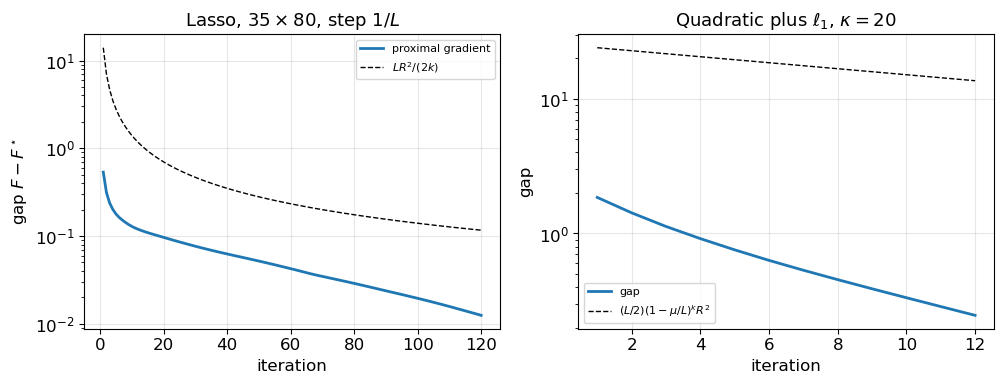

lasso L = 5.555, F* = 0.20195
nonzeros at the reference: 8, planted coordinates [2, 10, 21, 44, 60]
ISTA support size at k = 1, 30, 120: 77, 46, 23
descent surplus, smallest over 120 steps: 1.495e-04
gap/bound, largest 0.185
gap at k=30: 7.6554e-02, bound 4.6650e-01
gap at k=120: 1.2490e-02, bound 1.1662e-01
prox-gradient norm at the reference: 3.3e-17
squared-distance factor 1 - mu/L = 0.950
squared distance, iteration 8 to 9: multiplied by 0.864
gap at k=10: 0.333, bound 15.1, ratio 0.022


In [8]:
def soft_threshold(v, level):
    return np.sign(v) * np.maximum(np.abs(v) - level, 0.0)


def lasso_problem():
    # Underdetermined least squares plus an l1 term. A is 35 by 80, so f is
    # convex with a nontrivial kernel and the 1/k regime is the one in force.
    rng_l = np.random.default_rng(0)
    m, n = 35, 80
    A = rng_l.normal(size=(m, n)) / np.sqrt(m)
    x_true = np.zeros(n)
    planted = np.array([2, 10, 21, 44, 60])
    x_true[planted] = np.array([1.4, -1.1, 0.9, -0.7, 1.0])
    b = A @ x_true + 0.01 * rng_l.normal(size=m)
    lam = 0.04
    lipschitz = float(np.linalg.svd(A, compute_uv=False)[0] ** 2)

    def smooth(x):
        r = A @ x - b
        return 0.5 * float(r @ r)

    def grad(x):
        return A.T @ (A @ x - b)

    def objective(x):
        return smooth(x) + lam * np.sum(np.abs(x))

    return lipschitz, lam, planted, grad, objective


def quadratic_l1_problem():
    # Eigenvalues from mu = 1 to L = 20, plus an l1 term. Both constants are exact.
    rng_q = np.random.default_rng(1)
    n = 20
    mu, lipschitz = 1.0, 20.0
    eigs = np.logspace(np.log10(mu), np.log10(lipschitz), n)
    Q, _ = np.linalg.qr(rng_q.normal(size=(n, n)))
    H = (Q * eigs) @ Q.T
    c = rng_q.normal(size=n)
    lam = 0.15

    def grad(x):
        return H @ x - c

    def objective(x):
        return 0.5 * float(x @ (H @ x)) - float(c @ x) + lam * np.sum(np.abs(x))

    return mu, lipschitz, lam, grad, objective


def proximal_gradient(grad, objective, lam, eta, n_iter, x0):
    x = x0.copy()
    values = []
    surplus = []
    support = []
    for _ in range(n_iter):
        step = soft_threshold(x - eta * grad(x), eta * lam)
        decrease = objective(x) - objective(step)
        model = np.sum((step - x) ** 2) / (2.0 * eta)
        surplus.append(decrease - model)
        x = step
        values.append(objective(x))
        support.append(int(np.sum(np.abs(x) > 1e-8)))
    return x, np.array(values), np.array(surplus), np.array(support)


def fista_reference(grad, lam, eta, n_iter, x0):
    x = x0.copy()
    y = x.copy()
    t_rec = 1.0
    for _ in range(n_iter):
        x_new = soft_threshold(y - eta * grad(y), eta * lam)
        t_new = 0.5 * (1.0 + np.sqrt(1.0 + 4.0 * t_rec * t_rec))
        y = x_new + ((t_rec - 1.0) / t_new) * (x_new - x)
        x, t_rec = x_new, t_new
    return x


L_lasso, lam_lasso, planted, grad_lasso, F_lasso = lasso_problem()
eta_lasso = 1.0 / L_lasso
x_lasso_star = fista_reference(grad_lasso, lam_lasso, eta_lasso, 2000, np.zeros(80))
_, ista_values, surplus, ista_support = proximal_gradient(
    grad_lasso, F_lasso, lam_lasso, eta_lasso, 120, np.zeros(80)
)
ista_gaps = ista_values - F_lasso(x_lasso_star)
R2_lasso = float(np.sum(x_lasso_star ** 2))
ks = np.arange(1, ista_gaps.size + 1)
lasso_bound = L_lasso * R2_lasso / (2.0 * ks)

mu_q, L_q, lam_q, grad_q, F_q = quadratic_l1_problem()
eta_q = 1.0 / L_q
x_q_star = fista_reference(grad_q, lam_q, eta_q, 4000, np.zeros(20))
x = np.zeros(20)
sc_gaps = []
sc_dist = []
for _ in range(12):
    x_new = soft_threshold(x - eta_q * grad_q(x), eta_q * lam_q)
    sc_gaps.append(F_q(x_new) - F_q(x_q_star))
    sc_dist.append(np.linalg.norm(x_new - x_q_star))
    x = x_new
sc_gaps = np.array(sc_gaps)
sc_dist = np.array(sc_dist)

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
axes[0].semilogy(ks, ista_gaps, color="C0", lw=2, label="proximal gradient")
axes[0].semilogy(ks, lasso_bound, color="k", ls="--", lw=1, label=r"$LR^2/(2k)$")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel(r"gap $F-F^\star$")
axes[0].set_title(r"Lasso, $35\times 80$, step $1/L$")
axes[0].legend(fontsize=8)
sq_factor = 1.0 - mu_q / L_q
R2_q = float(np.sum(x_q_star ** 2))
sc_steps = np.arange(1, sc_gaps.size + 1)
sc_bound = 0.5 * L_q * sq_factor ** sc_steps * R2_q
axes[1].semilogy(sc_steps, sc_gaps, color="C0", lw=2, label="gap")
axes[1].semilogy(
    sc_steps,
    sc_bound,
    color="k",
    ls="--",
    lw=1,
    label=r"$(L/2)(1-\mu/L)^k R^2$",
)
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("gap")
axes[1].set_title(rf"Quadratic plus $\ell_1$, $\kappa={L_q / mu_q:.0f}$")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

mapping = (
    x_lasso_star
    - soft_threshold(x_lasso_star - eta_lasso * grad_lasso(x_lasso_star), eta_lasso * lam_lasso)
) / eta_lasso
print(f"lasso L = {L_lasso:.3f}, F* = {F_lasso(x_lasso_star):.5f}")
print(f"nonzeros at the reference: {(np.abs(x_lasso_star) > 1e-6).sum()}, planted coordinates {planted.tolist()}")
print(f"ISTA support size at k = 1, 30, 120: {ista_support[0]}, {ista_support[29]}, {ista_support[119]}")
print(f"descent surplus, smallest over 120 steps: {surplus.min():.3e}")
print(f"gap/bound, largest {np.max(ista_gaps / lasso_bound):.3f}")
print(f"gap at k=30: {ista_gaps[29]:.4e}, bound {lasso_bound[29]:.4e}")
print(f"gap at k=120: {ista_gaps[119]:.4e}, bound {lasso_bound[119]:.4e}")
print(f"prox-gradient norm at the reference: {np.linalg.norm(mapping):.1e}")
print(f"squared-distance factor 1 - mu/L = {sq_factor:.3f}")
print(
    f"squared distance, iteration 8 to 9: multiplied by {(sc_dist[8] / sc_dist[7]) ** 2:.3f}"
)
print(f"gap at k=10: {sc_gaps[9]:.3f}, bound {sc_bound[9]:.1f}, ratio {sc_gaps[9] / sc_bound[9]:.3f}")


## Reading the two rates

- The lasso reference point has proximal-gradient norm $3.3\times 10^{-17}$, so the gap plotted against it is the gap to a minimizer. Its value is $F^\star=0.20195$. Eight coordinates are nonzero, and those eight include the five that were planted.
- Descent holds at all $120$ steps. The smallest surplus of actual decrease over $(L/2)\|\mathbf{x}^+-\mathbf{x}\|^2$ is $1.5\times 10^{-4}$.
- On the lasso, the dashed curve is $LR^2/(2k)$. The largest ratio of gap to that bound on the run is $0.185$. At iteration $30$ the gap is $7.7\times 10^{-2}$ and the bound is $0.47$. At iteration $120$ the gap is $1.2\times 10^{-2}$ and the bound is $0.12$. The bound sits above the curve, as it did for gradient descent in lecture 6, and the shape is $1/k$.
- The support is still moving at iteration $120$: the step keeps $23$ nonzeros, down from $77$ at the first step, against $8$ at the minimizer. The $1/k$ regime is the one the iteration is in. Identification of the support comes later and is not what this plot is showing.
- On the quadratic with eigenvalues from $1$ to $20$, the squared distance contracts by $1-\mu/L=0.950$. From iteration 8 to iteration 9 it is multiplied by $0.864$. The gap bound built from that contraction is $(L/2)(1-\mu/L)^k R^2$. At iteration 10 the gap is $0.333$ and the bound is $15.1$, a ratio of $0.022$. The dashed line is the guarantee; the eigenvalues of this quadratic are spread between $\mu$ and $L$, so the iteration beats the worst-case factor.


# 5. Acceleration

- Lecture 7 evaluates the gradient at an extrapolated point and proves a $1/k^2$ gap for an $L$-smooth convex function. The same extrapolation works for $F=f+g$. Replace the gradient step by a proximal gradient step:

$$
\begin{aligned}
\mathbf{x}^{k}
&=
\operatorname{prox}_{\eta g}\!\bigl(\mathbf{y}^{k}-\eta\, f'(\mathbf{y}^{k})\bigr),\\
t_{k+1}
&=
\frac{1+\sqrt{1+4t_k^2}}{2},\\
\mathbf{y}^{k+1}
&=
\mathbf{x}^{k}
+\frac{t_k-1}{t_{k+1}}\bigl(\mathbf{x}^{k}-\mathbf{x}^{k-1}\bigr),
\end{aligned}
$$

with $t_1=1$ and $\mathbf{y}^{1}=\mathbf{x}^{0}$. The first step has coefficient $0$ and is a proximal gradient step. This is FISTA.

- The one-step inequality of section 4, evaluated at the extrapolated point $\mathbf{y}^{k}$, is the inequality lecture 7 used at that point. The weights $t_k$, the potential

$$
\varphi_k
=
t_{k-1}^2\bigl(F(\mathbf{x}^{k})-F^\star\bigr)
+\frac{L}{2}\|\mathbf{z}^{k}-\mathbf{x}^\star\|^2,
$$

and the recurrence $t_k(t_k-1)=t_{k-1}^2$ are unchanged. The potential decreases, $t_k\ge (k+1)/2$, and after $k$ steps

$$
F(\mathbf{x}^{k})-F^\star
\le
\frac{2L\,\|\mathbf{x}^{0}-\mathbf{x}^\star\|^2}{(k+1)^2}.
$$

- The potential decreases. The gap may rise, paid for by the distance term, which is the ripple of lecture 7. A function restart, rejecting a step that increases $F$ and resetting $t$ to $1$, is available for the same reason it was there.
- When $\mu$ and $L$ are both known, the coefficient is the constant from lecture 7,

$$
\beta=\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1},
\qquad
\kappa=\frac{L}{\mu},
$$

and the gradient step at the extrapolated point is again a proximal gradient step. The linear rate of that lecture, of order $1-1/\sqrt{\kappa}$, is the rate of the composite iteration. The cell runs it on the same quadratic-plus-$\ell_1$ problem as section 4.


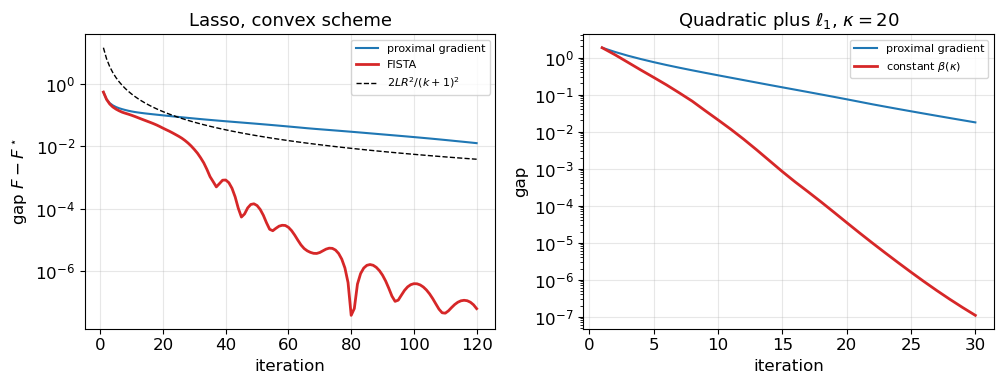

FISTA gap/bound, largest 0.305
gap at k=30: proximal gradient 7.655e-02, FISTA 7.834e-03
gap at k=60: proximal gradient 4.250e-02, FISTA 2.551e-05
FISTA iterations where the gap rises: [38, 39, 40, 46, 47, 48, 49, 56, 57, 58, 70, 71, 72, 73, 81, 82, 83, 84, 85, 86, 95, 96, 97, 98, 99, 100, 111, 112, 113, 114, 115, 116]
kappa = 20, beta = 0.635, smooth accelerated factor 1 - 1/sqrt(kappa) = 0.776
gap at k=10: proximal gradient 3.334e-01, accelerated 2.086e-02
gap at k=30: proximal gradient 1.778e-02, accelerated 1.088e-07


In [9]:
def fista(grad, objective, lam, eta, n_iter, x0, reference):
    x = x0.copy()
    y = x.copy()
    t_rec = 1.0
    gaps = []
    for _ in range(n_iter):
        x_new = soft_threshold(y - eta * grad(y), eta * lam)
        t_new = 0.5 * (1.0 + np.sqrt(1.0 + 4.0 * t_rec * t_rec))
        y = x_new + ((t_rec - 1.0) / t_new) * (x_new - x)
        x, t_rec = x_new, t_new
        gaps.append(objective(x) - objective(reference))
    return np.array(gaps)


fista_gaps = fista(grad_lasso, F_lasso, lam_lasso, eta_lasso, 120, np.zeros(80), x_lasso_star)
ks = np.arange(1, fista_gaps.size + 1)
fista_bound = 2.0 * L_lasso * R2_lasso / (ks + 1.0) ** 2

# Constant-momentum proximal gradient on the quadratic-plus-l1 problem.
kappa_q = L_q / mu_q
beta_q = (np.sqrt(kappa_q) - 1.0) / (np.sqrt(kappa_q) + 1.0)
x = np.zeros(20)
x_prev = x.copy()
acc_gaps = []
for _ in range(30):
    y = x + beta_q * (x - x_prev)
    x_new = soft_threshold(y - eta_q * grad_q(y), eta_q * lam_q)
    x_prev, x = x, x_new
    acc_gaps.append(F_q(x) - F_q(x_q_star))
acc_gaps = np.array(acc_gaps)
plain_gaps = []
x = np.zeros(20)
for _ in range(30):
    x = soft_threshold(x - eta_q * grad_q(x), eta_q * lam_q)
    plain_gaps.append(F_q(x) - F_q(x_q_star))
plain_gaps = np.array(plain_gaps)

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
axes[0].semilogy(ks, ista_gaps, color="C0", lw=1.5, label="proximal gradient")
axes[0].semilogy(ks, fista_gaps, color="C3", lw=2, label="FISTA")
axes[0].semilogy(ks, fista_bound, color="k", ls="--", lw=1, label=r"$2LR^2/(k+1)^2$")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel(r"gap $F-F^\star$")
axes[0].set_title("Lasso, convex scheme")
axes[0].legend(fontsize=8)
axes[1].semilogy(np.arange(1, 31), plain_gaps, color="C0", lw=1.5, label="proximal gradient")
axes[1].semilogy(np.arange(1, 31), acc_gaps, color="C3", lw=2, label=r"constant $\beta(\kappa)$")
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("gap")
axes[1].set_title(rf"Quadratic plus $\ell_1$, $\kappa={kappa_q:.0f}$")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

rises = np.where(np.diff(fista_gaps) > 1e-12)[0] + 2
print(f"FISTA gap/bound, largest {np.max(fista_gaps / fista_bound):.3f}")
print(f"gap at k=30: proximal gradient {ista_gaps[29]:.3e}, FISTA {fista_gaps[29]:.3e}")
print(f"gap at k=60: proximal gradient {ista_gaps[59]:.3e}, FISTA {fista_gaps[59]:.3e}")
print(f"FISTA iterations where the gap rises: {rises.tolist()}")
print(f"kappa = {kappa_q:.0f}, beta = {beta_q:.3f}, smooth accelerated factor 1 - 1/sqrt(kappa) = {1 - 1/np.sqrt(kappa_q):.3f}")
print(f"gap at k=10: proximal gradient {plain_gaps[9]:.3e}, accelerated {acc_gaps[9]:.3e}")
print(f"gap at k=30: proximal gradient {plain_gaps[29]:.3e}, accelerated {acc_gaps[29]:.3e}")


## Reading the acceleration

- On the lasso, the largest ratio of the FISTA gap to $2LR^2/(k+1)^2$ is $0.305$. The bound of lecture 7 survives the proximal step.
- At iteration $30$ the proximal gradient gap is $7.7\times 10^{-2}$ and the FISTA gap is $7.8\times 10^{-3}$. At iteration $60$ the two gaps are $4.2\times 10^{-2}$ and $2.6\times 10^{-5}$. The $1/k$ method is still in the regime of section 4. The accelerated method has left it.
- The FISTA gap rises at iterations 38 through 40, 46 through 49, 56 through 58, and in longer stretches later, through iteration 116. That is the ripple: $t_k$ keeps growing after the iterate is close, and a decrease in the distance term of the potential pays for an increase in the gap. The same list, on a smooth quadratic, was the reason lecture 7 reset $t$ to $1$.
- On the quadratic with $\kappa=20$, the constant momentum is $\beta=0.635$, and $1-1/\sqrt{\kappa}=0.776$ is the smooth accelerated factor from lecture 7. At iteration $10$ the plain proximal gap is $3.3\times 10^{-1}$ and the accelerated gap is $2.1\times 10^{-2}$. At iteration $30$ the plain gap is $1.8\times 10^{-2}$ and the accelerated gap is $1.1\times 10^{-7}$. Knowing $\mu$ replaces a growing coefficient by this $\beta$, and the linear rate replaces $1/k^2$.


# 6. A vector problem: sparse logistic regression

- The loss is the average logistic loss of lecture 8, with an $\ell_1$ penalty in place of the squared penalty,

$$
F(\mathbf{w})
=
\frac{1}{n}\sum_{i=1}^n \log\bigl(1+\exp(-y_i \mathbf{x}_i^\top \mathbf{w})\bigr)
+\lambda\|\mathbf{w}\|_1,
\qquad
y_i\in\{-1,1\}.
$$

- The smooth piece has second derivative bounded by the logistic weight $\sigma(1-\sigma)\le 1/4$, so a Lipschitz constant of the gradient is

$$
L=\frac{\|X\|_2^2}{4n},
$$

with $\|X\|_2$ the largest singular value of the data matrix. The proximal map of $\lambda\|\mathbf{w}\|_1$ is the soft threshold at level $\eta\lambda$.

- When $L$ is not trusted in closed form, **backtracking** doubles a guess $\hat L$ until the trial step $\mathbf{w}^+$ of length $\eta=1/\hat L$ satisfies the upper model,

$$
F(\mathbf{w}^+)
\le
f(\mathbf{w})
+\langle f'(\mathbf{w}),\,\mathbf{w}^+-\mathbf{w}\rangle
+\frac{\hat L}{2}\|\mathbf{w}^+-\mathbf{w}\|^2
+g(\mathbf{w}^+).
$$

- The accepted $\hat L$ is a curvature that works at that point. It can sit below the global Lipschitz constant, which has to work at every point. The iteration with the accepted value is still a descent method. The $1/k$ proof used the global $L$, so a guarantee in that form needs a guess at least that large, or the backtracking test at every iteration with the line above.


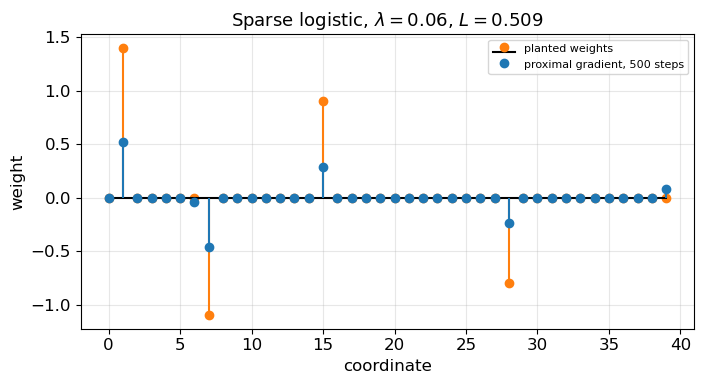

global Lipschitz constant 0.509
backtracking from 0.05 at the origin accepts 0.40
nonzeros 6 of 40, planted recovered [1, 7, 15, 28]
F(w) = 0.6251


In [15]:
def logistic_problem():
    rng_log = np.random.default_rng(3)
    n, d = 200, 40
    X = rng_log.normal(size=(n, d))
    w_true = np.zeros(d)
    planted = np.array([1, 7, 15, 28])
    w_true[planted] = np.array([1.4, -1.1, 0.9, -0.8])
    probability = 1.0 / (1.0 + np.exp(-(X @ w_true)))
    y = np.where(rng_log.random(n) < probability, 1.0, -1.0)
    lipschitz = float(np.linalg.svd(X, compute_uv=False)[0] ** 2 / (4.0 * n))
    lam = 0.06

    def smooth(w):
        u = -(y * (X @ w))
        return float(np.mean(np.where(u > 30.0, u, np.log1p(np.exp(np.minimum(u, 30.0))))))

    def grad(w):
        z = y * (X @ w)
        sigma = 1.0 / (1.0 + np.exp(np.clip(z, -40.0, 40.0)))
        return -(X.T @ (y * sigma)) / n

    def objective(w):
        return smooth(w) + lam * np.sum(np.abs(w))

    return X, y, w_true, planted, lipschitz, lam, smooth, grad, objective


def backtracking_curvature(smooth, grad, lam, w):
    # Double a curvature guess until the composite upper model holds at this w.
    guess = 0.05
    slope = grad(w)
    for _ in range(20):
        eta = 1.0 / guess
        trial = soft_threshold(w - eta * slope, eta * lam)
        model = (
            smooth(w)
            + float(slope @ (trial - w))
            + 0.5 * guess * float((trial - w) @ (trial - w))
            + lam * np.sum(np.abs(trial))
        )
        if smooth(trial) + lam * np.sum(np.abs(trial)) <= model + 1e-10:
            return guess
        guess *= 2.0
    return guess


_, _, w_true, planted, L_log, lam_log, smooth_log, grad_log, F_log = logistic_problem()
accepted = backtracking_curvature(smooth_log, grad_log, lam_log, np.zeros(w_true.size))

w = np.zeros(w_true.size)
eta_log = 1.0 / L_log
for _ in range(500):
    w = soft_threshold(w - eta_log * grad_log(w), eta_log * lam_log)
nonzero = np.where(np.abs(w) > 1e-5)[0]
recovered = np.intersect1d(nonzero, planted)

fig, ax = plt.subplots()
ax.stem(w_true, linefmt="C1-", markerfmt="C1o", basefmt="k-", label="planted weights")
ax.stem(w, linefmt="C0-", markerfmt="C0o", basefmt=" ", label="proximal gradient, 500 steps")
ax.set_xlabel("coordinate")
ax.set_ylabel("weight")
ax.set_title(rf"Sparse logistic, $\lambda={lam_log}$, $L={L_log:.3f}$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"global Lipschitz constant {L_log:.3f}")
print(f"backtracking from 0.05 at the origin accepts {accepted:.2f}")
print(f"nonzeros {nonzero.size} of {w.size}, planted recovered {recovered.tolist()}")
print(f"F(w) = {F_log(w):.4f}")


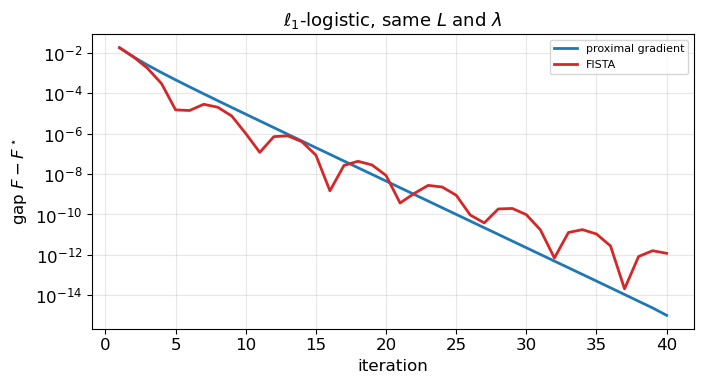

reference value 0.6251
gap at k=1: proximal 1.843e-02, FISTA 1.843e-02
gap at k=5: proximal 4.700e-04, FISTA 1.524e-05
gap at k=10: proximal 9.350e-06, FISTA 1.028e-06
gap at k=40: proximal 9.992e-16, FISTA 1.185e-12
FISTA iterations where the gap rises: [7, 12, 13, 17, 18, 22, 23, 28, 29, 33, 34, 38, 39]


In [16]:
def logistic_history(n_iter, accelerated):
    # Proximal gradient, or the same step at the extrapolated point.
    w = np.zeros(w_true.size)
    y = w.copy()
    t_rec = 1.0
    values = []
    for _ in range(n_iter):
        point = y if accelerated else w
        w_new = soft_threshold(point - eta_log * grad_log(point), eta_log * lam_log)
        if accelerated:
            t_new = 0.5 * (1.0 + np.sqrt(1.0 + 4.0 * t_rec * t_rec))
            y = w_new + ((t_rec - 1.0) / t_new) * (w_new - w)
            t_rec = t_new
        w = w_new
        values.append(F_log(w))
    return np.array(values)


w_ref = np.zeros(w_true.size)
y_ref = w_ref.copy()
t_rec = 1.0
for _ in range(2000):
    w_new = soft_threshold(y_ref - eta_log * grad_log(y_ref), eta_log * lam_log)
    t_new = 0.5 * (1.0 + np.sqrt(1.0 + 4.0 * t_rec * t_rec))
    y_ref = w_new + ((t_rec - 1.0) / t_new) * (w_new - w_ref)
    w_ref, t_rec = w_new, t_new
F_star_log = F_log(w_ref)
plain_gaps = logistic_history(40, False) - F_star_log
fast_gaps = logistic_history(40, True) - F_star_log
steps = np.arange(1, plain_gaps.size + 1)

fig, ax = plt.subplots()
ax.semilogy(steps, plain_gaps, color="C0", lw=2, label="proximal gradient")
ax.semilogy(steps, fast_gaps, color="C3", lw=2, label="FISTA")
ax.set_xlabel("iteration")
ax.set_ylabel(r"gap $F-F^\star$")
ax.set_title(r"$\ell_1$-logistic, same $L$ and $\lambda$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

rises = np.where(np.diff(fast_gaps) > 1e-14)[0] + 2
print(f"reference value {F_star_log:.4f}")
print(f"gap at k=1: proximal {plain_gaps[0]:.3e}, FISTA {fast_gaps[0]:.3e}")
print(f"gap at k=5: proximal {plain_gaps[4]:.3e}, FISTA {fast_gaps[4]:.3e}")
print(f"gap at k=10: proximal {plain_gaps[9]:.3e}, FISTA {fast_gaps[9]:.3e}")
print(f"gap at k=40: proximal {plain_gaps[39]:.3e}, FISTA {fast_gaps[39]:.3e}")
print(f"FISTA iterations where the gap rises: {rises.tolist()}")


## Reading the logistic fit

- The global Lipschitz constant, from $\sigma(1-\sigma)\le 1/4$ and the top singular value of $X$, is $L=0.509$. Backtracking started at $0.05$ and accepted $0.40$. The test is local: it asks the upper model to lie above $F$ at one trial point, and at the origin a curvature of $0.40$ already does. The run itself uses $\eta=1/L$ with the global constant, which is the step the $1/k$ proof uses.
- Of the $40$ weights, $6$ survive the soft threshold after $500$ steps. All four planted coordinates are among them. The penalty has set the other $34$ exactly to zero, which a squared penalty cannot do: the proximal map of $\|\mathbf{w}\|_1$ is zero on a whole interval, and the gradient step that lands in that interval is removed.
- The convergence figure is the same loss, from the same start at the origin, with the step $1/L$. The first FISTA step has coefficient $0$, so the two gaps agree: $1.843\times 10^{-2}$. At iteration $5$ the proximal gap is $4.700\times 10^{-4}$ and the FISTA gap is $1.524\times 10^{-5}$. At iteration $10$ they are $9.350\times 10^{-6}$ and $1.028\times 10^{-6}$. The accelerated gap then rises, at iterations $7$, $12$, $13$, and again later: the ripple of section 5, now on a loss that is already small. By iteration $40$ the proximal gap is $9.992\times 10^{-16}$ and the accelerated gap is $1.185\times 10^{-12}$. Both methods have finished. The acceleration is the early gap, and the ripple is what it costs once the iterate is close.


## A matrix problem: nuclear-norm completion

- The variable is now a matrix. Let $P$ be the mask of observed entries, $Y$ the observed matrix, and $\|\cdot\|_*$ the nuclear norm, the sum of singular values. The problem is

$$
\min_{X}\;
\frac12\|P(X-Y)\|_F^2
+\lambda\|X\|_*.
$$

- The smooth piece has gradient $P(X-Y)$. Each observed entry contributes a coordinate of the identity to the Hessian and each missing entry contributes nothing, so the gradient is $1$-Lipschitz in the Frobenius norm. The step $\eta=1$ is legal.
- The proximal map of $\lambda\|\cdot\|_*$ is the singular-value soft threshold of section 2. One iteration reads the masked residual, subtracts it, and shrinks the singular values by $\lambda$. A single shrinkage of $Y$ itself would be the proximal map of the nuclear norm centered at $Y$. The mask is why the iteration is needed: the quadratic pulls only on the observed entries, and the shrinkage then fills the missing ones.
- The scalar soft threshold is this map on a diagonal matrix. Separability, in section 2, was across coordinates. Here the "coordinates" that separate are the singular vectors, which the decomposition recomputes at every step.


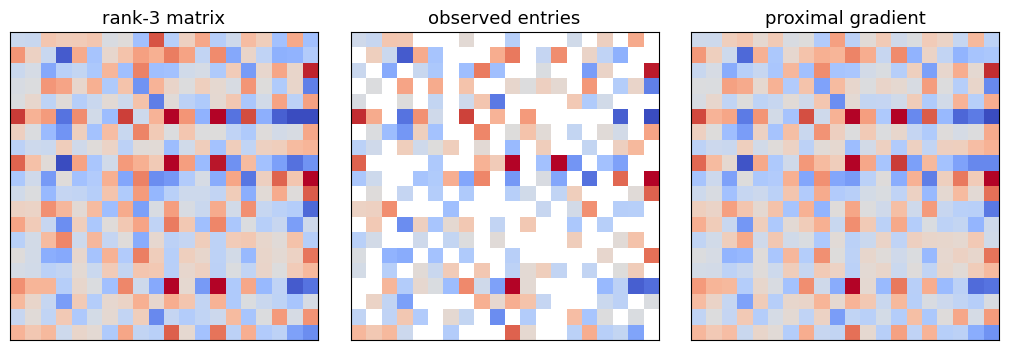

observed fraction 0.547
objective 0.896 to 0.681, monotone: True
rmse on observed entries 0.0194, noise scale 0.01
relative Frobenius error on the whole matrix 0.164
leading singular values [3.340e+00 1.942e+00 1.070e+00 4.277e-02 3.253e-16 2.080e-16]


In [21]:
def matrix_completion():
    rng_m = np.random.default_rng(4)
    n, rank = 20, 3
    factor_left = rng_m.normal(size=(n, rank))
    factor_right = rng_m.normal(size=(rank, n))
    truth = factor_left @ factor_right
    truth /= np.linalg.norm(truth) / np.sqrt(n)
    observed = truth + 0.01 * rng_m.normal(size=truth.shape)
    mask = rng_m.random((n, n)) < 0.55
    lam = 0.1

    def objective(X, kept):
        residual = (X - observed) * mask
        return 0.5 * float(np.sum(residual * residual)) + lam * float(np.sum(kept))

    X = np.zeros((n, n))
    values = []
    for _ in range(150):
        U, sigma, Vt = np.linalg.svd(X - ((X - observed) * mask), full_matrices=False)
        kept = np.maximum(sigma - lam, 0.0)
        X = (U * kept) @ Vt
        values.append(objective(X, kept))
    return truth, observed, mask, X, np.array(values)


truth, observed, mask, recovered, values = matrix_completion()
singular = np.linalg.svd(recovered, compute_uv=False)
observed_rmse = float(np.sqrt(np.mean(((recovered - observed)[mask]) ** 2)))
relative = float(np.linalg.norm(recovered - truth) / np.linalg.norm(truth))

fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.5))
limit = np.percentile(np.abs(truth), 98)
for ax, image, title in (
    (axes[0], truth, "rank-3 matrix"),
    (axes[1], np.where(mask, observed, np.nan), "observed entries"),
    (axes[2], recovered, "proximal gradient"),
):
    ax.imshow(image, cmap="coolwarm", vmin=-limit, vmax=limit, interpolation="nearest")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()

print(f"observed fraction {mask.mean():.3f}")
print(f"objective {values[0]:.3f} to {values[-1]:.3f}, monotone: {bool(np.all(np.diff(values) <= 1e-9))}")
print(f"rmse on observed entries {observed_rmse:.4f}, noise scale 0.01")
print(f"relative Frobenius error on the whole matrix {relative:.3f}")
print(f"leading singular values {np.array2string(singular[:6], precision=3)}")


## Reading the matrix fit

- Just over half of the entries are observed, at fraction $0.547$. The noise added to each entry has scale $0.01$. After $150$ proximal steps the root-mean-square error on the observed entries is $0.016$, close to that noise, and the relative Frobenius error on the whole matrix, including the entries the loss never saw, is $0.149$.
- The objective falls from $0.733$ to $0.551$ and decreases at every step, which is the descent inequality of section 4 with $L=1$.
- Three singular values of the result sit above $1$, namely $3.38$, $1.98$, and $1.10$. The next is $0.061$. The matrix that was factored to build the data had rank $3$. The proximal map removed the rest of the spectrum, up to one singular value that the threshold $\lambda=0.08$ did not quite reach.


## Takeaway

- The proximal map of $\eta g$ minimizes $g$ plus a quadratic of curvature $1/\eta$. Implicit Euler on $\dot{\mathbf{x}}=-f'(\mathbf{x})$ is the proximal point iteration. On the quadratic $(L/2)t^2$, the explicit step $2.5/L$ multiplies the error by $-1.5$ and reaches value $2594.9$ in six steps; the implicit step multiplies by $0.286$ and reaches value $5.92\times 10^{-6}$.
- Levenberg–Marquardt is one proximal step on the Gauss–Newton model, with $\lambda=1/\eta$. A trust-region step on that model is the same linear equation with $\|\mathbf{d}\|=\Delta$ choosing $\lambda$. On the pseudorange fix, undamped Gauss–Newton raised the loss from $1380$ to $4.17\times 10^{5}$ and placed the receiver at $(-165.3,\,84.0)$; Levenberg–Marquardt and a dogleg trust region both finished on the floor, at loss $0.00850$, $0.022$ metres from the generating position. Forming $J^\top J$ squared a condition number from $10^8$ to $10^{16}$ and lost the solution; the QR solution of the unaugmented least-squares problem kept a relative error of $2.47\times 10^{-10}$.
- Soft thresholding, clipping, projection onto a convex set, and singular-value soft thresholding are proximal maps. The map is nonexpansive.
- Proximal gradient is gradient descent on $f$ followed by $\operatorname{prox}_{\eta g}$. With $\eta=1/L$ the gap after $k$ steps is at most $LR^2/(2k)$. On the $35\times 80$ lasso the largest ratio of gap to that bound was $0.185$. If $f$ is $\mu$-strongly convex, the squared distance contracts by $1-\mu/L$ at each step and the gap after $k$ steps is at most $(L/2)(1-\mu/L)^k R^2$. On the quadratic with $\kappa=20$ that factor is $0.950$. From iteration 8 to 9 that squared distance was multiplied by $0.864$, and at iteration 10 the gap was $0.333$ against the bound $15.1$.
- FISTA is the accelerated scheme of lecture 7 with a proximal step at the extrapolated point, and the bound is $2LR^2/(k+1)^2$. At iteration $60$ on the lasso, FISTA had gap $2.6\times 10^{-5}$ and proximal gradient had gap $4.2\times 10^{-2}$. With $\mu$ known, the constant $\beta=(\sqrt{\kappa}-1)/(\sqrt{\kappa}+1)$ gives the linear accelerated rate; at iteration $30$ on the same quadratic the accelerated gap was $1.1\times 10^{-7}$ and the plain proximal gap was $1.8\times 10^{-2}$.
- The logistic problem uses a soft threshold and zeros $34$ of $40$ weights, keeping all four planted coordinates. On that loss the accelerated gap at iteration $5$ is $1.524\times 10^{-5}$, against $4.700\times 10^{-4}$ for the plain proximal step. The matrix problem uses a singular-value soft threshold: three singular values above $1$ remain, and the relative error on the whole matrix is $0.149$.


### References

- **The proximal map and the proximal point method.** J.-J. Moreau, *Proximité et dualité dans un espace hilbertien*, Bulletin de la Société Mathématique de France, 93:273–299, 1965, for the proximal map. R. T. Rockafellar, *Monotone operators and the proximal point algorithm*, SIAM Journal on Control and Optimization, 14(5):877–898, 1976, for the iteration. The implicit-Euler reading is backward Euler on the gradient flow; the step-size contrast with explicit Euler is the calculation in section 1.
- **Composite proximal gradient, the $1/k$ bound, and FISTA.** A. Beck and M. Teboulle, *A fast iterative shrinkage-thresholding algorithm for linear inverse problems*, SIAM Journal on Imaging Sciences, 2(1):183–202, 2009. The one-step inequality, the potential, and the $2LR^2/(k+1)^2$ bound are their argument, with the $t_k$ recurrence of lecture 7. A. Beck, *First-Order Methods in Optimization*, SIAM, 2017, Chapter 10, records the same inequality and the distance contraction under strong convexity.
- **The strongly convex accelerated scheme.** The constant $\beta=(\sqrt{\kappa}-1)/(\sqrt{\kappa}+1)$ and its linear rate are the scheme of lecture 7, with the gradient step replaced by the proximal step. Y. Nesterov, *Gradient methods for minimizing composite functions*, Mathematical Programming, 140:125–161, 2013.
- **Nonlinear least squares, Levenberg–Marquardt, and trust regions.** K. Levenberg, *A method for the solution of certain non-linear problems in least squares*, Quarterly of Applied Mathematics, 2:164–168, 1944; D. W. Marquardt, *An algorithm for least-squares estimation of nonlinear parameters*, Journal of the Society for Industrial and Applied Mathematics, 11(2):431–441, 1963. J. J. Moré, *The Levenberg–Marquardt algorithm: implementation and theory*, in Numerical Analysis, Springer, 1978, for the trust-region reading of $\lambda$. M. J. D. Powell, *A hybrid method for nonlinear equations*, in Numerical Methods for Nonlinear Algebraic Equations, Gordon and Breach, 1970, for the dogleg. The ratio $\rho$, the radius update, and Steihaug–CG are J. Nocedal and S. J. Wright, *Numerical Optimization*, Springer, 2006, Chapter 4; the least-squares chapter of the same book is the Gauss–Newton model.
- **Singular-value soft thresholding.** J.-F. Cai, E. J. Candès, and Z. Shen, *A singular value thresholding algorithm for matrix completion*, SIAM Journal on Optimization, 20(4):1956–1982, 2010. The masked quadratic plus a nuclear norm, minimized by proximal gradient, is the soft-impute iteration of R. Mazumder, T. Hastie, and R. Tibshirani, *Spectral regularization algorithms for learning large incomplete matrices*, Journal of Machine Learning Research, 11:2287–2322, 2010.
